# Diabetes Prediction using Machine Learning




This project applies machine learning classification algorithms to predict whether a patient is likely to have diabetes based on diagnostic and health-related features.

## 1. Import Required Libraries


The required libraries are imported for data manipulation, visualization, preprocessing, model training, and evaluation.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn import metrics

## 2. Load the Dataset


The diabetes dataset is loaded into a Pandas DataFrame for exploration and preprocessing.

In [59]:
df = pd.read_excel('pima-dataset.xlsx')

df.head()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,has_diabetes,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True,True


## 3. Explore the Dataset


The dataset structure, dimensions, column names, and statistical information are inspected to understand the available features and target variable.

In [60]:
df.shape

(768, 12)

In [61]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'thickness', 'insulin',
       'bmi', 'diab_pred', 'age', 'diabetes_orig', 'skin', 'has_diabetes',
       'diabetes'],
      dtype='object')

In [62]:
df.describe()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958,0.809136
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951,0.628517
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000,0.906200
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000,1.260800
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000,3.900600


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_preg       768 non-null    int64  
 1   glucose_conc   768 non-null    int64  
 2   diastolic_bp   768 non-null    int64  
 3   thickness      768 non-null    int64  
 4   insulin        768 non-null    int64  
 5   bmi            768 non-null    float64
 6   diab_pred      768 non-null    float64
 7   age            768 non-null    int64  
 8   diabetes_orig  768 non-null    int64  
 9   skin           768 non-null    float64
 10  has_diabetes   768 non-null    bool   
 11  diabetes       768 non-null    bool   
dtypes: bool(2), float64(3), int64(7)
memory usage: 61.6 KB


## 4. Data Cleaning


The dataset is checked for missing values and potential issues before preparing it for machine learning models.

### Check Zero Values


Some medical measurements contain zero values that are not meaningful for those measurements. These values are treated as missing values during preprocessing.

In [64]:
columns_to_check = ['glucose_conc','diastolic_bp','insulin','bmi','skin']

for column in columns_to_check:
    zero_count = (df[column] == 0).sum()
    print(f"{column}: {zero_count}")

glucose_conc: 5
diastolic_bp: 35
insulin: 374
bmi: 11
skin: 227


## 5. Prepare Features and Target


The input features are separated from the target variable. The `diabetes` column represents the outcome that the models will predict.

In [65]:
input_columns = ['num_preg','glucose_conc','diastolic_bp','insulin','bmi', 'diab_pred','age','skin']
X = df[input_columns]
y = df['diabetes']

## 6. Train-Test Split


The dataset is divided into training and testing sets. The training data is used to train the models, while the test data is used to evaluate their performance on unseen patients.

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=42)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (537, 8)
Testing features: (231, 8)
Training target: (537,)
Testing target: (231,)


## 7. Handle Missing Values


Zero values representing missing measurements are replaced with the mean calculated from the training data. The same imputation strategy is then applied to the test data.

In [67]:
imputer = SimpleImputer(missing_values=0, strategy='mean')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

## 8. Feature Scaling


Feature scaling standardizes the input features so that variables with different numerical ranges can be processed more effectively by the machine learning models.

In [68]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 9. Train the Naive Bayes Model


A Gaussian Naive Bayes classifier is trained as one of the baseline models for diabetes classification.

In [69]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

nb_accuracy = metrics.accuracy_score(y_test, nb_pred)

print(f"Naive Bayes Test Accuracy: {nb_accuracy:.2%}")

Naive Bayes Test Accuracy: 74.03%


## 10. Train the Random Forest Model


A Random Forest classifier is trained using multiple decision trees to capture patterns in the patient data and predict diabetes outcomes.

In [70]:
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = metrics.accuracy_score(y_test, rf_pred)

print(f"Random Forest Test Accuracy: {rf_accuracy:.2%}")

Random Forest Test Accuracy: 75.32%


## 11. Train the K-Nearest Neighbors Model


The K-Nearest Neighbors classifier predicts the diabetes outcome based on the similarity between patients in the feature space.

In [71]:
knn_model = KNeighborsClassifier()

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

knn_accuracy = metrics.accuracy_score(y_test, knn_pred)

print(f"KNN Test Accuracy: {knn_accuracy:.2%}")

KNN Test Accuracy: 68.40%


## 12. Model Evaluation


The trained models are evaluated using accuracy, confusion matrices, and classification reports to compare their performance on the test dataset.

In [72]:
print("Naive Bayes Classification Report")
print(metrics.classification_report(y_test, nb_pred))

Naive Bayes Classification Report
              precision    recall  f1-score   support

       False       0.81      0.79      0.80       151
        True       0.62      0.65      0.63        80

    accuracy                           0.74       231
   macro avg       0.71      0.72      0.72       231
weighted avg       0.74      0.74      0.74       231



In [73]:
print("Random Forest Classification Report")
print(metrics.classification_report(y_test, rf_pred))

Random Forest Classification Report
              precision    recall  f1-score   support

       False       0.82      0.80      0.81       151
        True       0.64      0.66      0.65        80

    accuracy                           0.75       231
   macro avg       0.73      0.73      0.73       231
weighted avg       0.76      0.75      0.75       231



In [74]:
print("KNN Classification Report")
print(metrics.classification_report(y_test, knn_pred))

KNN Classification Report
              precision    recall  f1-score   support

       False       0.77      0.74      0.75       151
        True       0.54      0.59      0.56        80

    accuracy                           0.68       231
   macro avg       0.66      0.66      0.66       231
weighted avg       0.69      0.68      0.69       231



## 13. Compare Model Performance


The test accuracies of the three machine learning models are compared to identify the best-performing model for this dataset.

In [75]:
model_results = pd.DataFrame({
    'Model': ['Naive Bayes', 'Random Forest', 'KNN'],
    'Test Accuracy': [
        nb_accuracy,
        rf_accuracy,
        knn_accuracy
    ]
})
model_results

,Model,Test Accuracy
0,Naive Bayes,0.740260
1,Random Forest,0.753247
2,KNN,0.683983


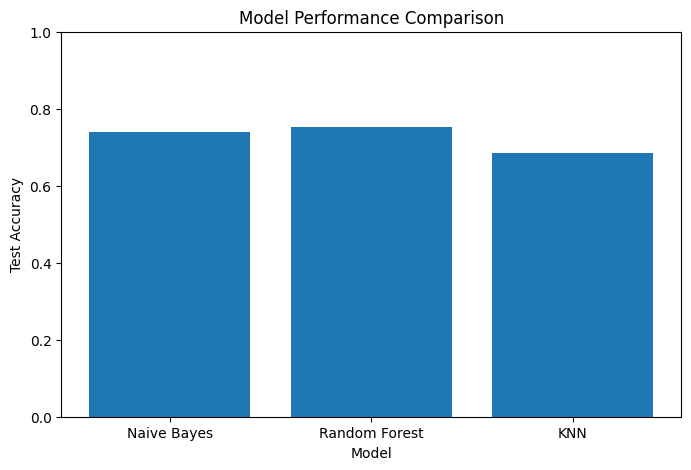

In [76]:
# visualization
plt.figure(figsize=(8, 5))

plt.bar(
    model_results['Model'],
    model_results['Test Accuracy']
)

plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.title('Model Performance Comparison')
plt.ylim(0, 1)

plt.show()

## 14. Random Forest Confusion Matrix


The confusion matrix shows the number of correctly and incorrectly classified diabetic and non-diabetic patients using the Random Forest model.

In [77]:
confusion_matrix = metrics.confusion_matrix(y_test, rf_pred)

print("Random Forest Confusion Matrix:")
print(confusion_matrix)

Random Forest Confusion Matrix:
[[121  30]
 [ 27  53]]


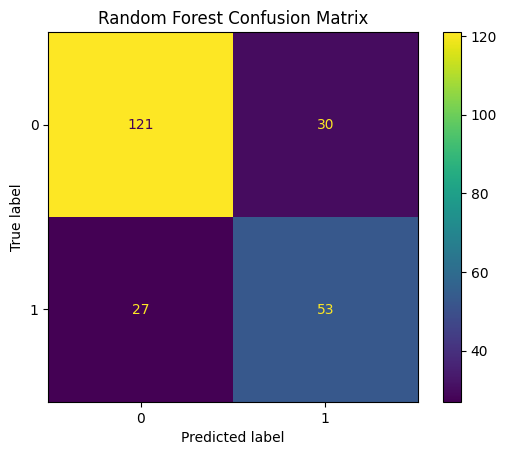

In [78]:
metrics.ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix
).plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

## 15. Individual Patient Prediction


The trained Random Forest model is used to predict the diabetes outcome for an individual patient using the same preprocessing steps applied during model training.

In [79]:
input_data = pd.DataFrame(
    [[2, 197, 70, 543, 30.5, 0.158, 53, 1.773]],
    columns=input_columns
)

input_data = imputer.transform(input_data)
input_data = scaler.transform(input_data)

prediction = rf_model.predict(input_data)

print(
    "Prediction:",
    "Diabetic" if prediction[0] == 1 else "Not Diabetic"
)

Prediction: Diabetic


## 16. Conclusion

Three machine learning classification algorithms — Naive Bayes, Random Forest, and KNN — were trained to predict diabetes using patient health-related features.
Among the three models, Random Forest achieved the highest test accuracy of approximately **75.32%** in the existing results. The project demonstrates the complete machine learning workflow, including data exploration, handling missing values, feature scaling, model training, evaluation, and individual patient prediction.